# MVP — Triagem de Risco Materno com Machine Learning

**Pós-graduação em Engenharia de Software — PUC-Rio**
**Disciplina:** Engenharia de Sistemas de Software Inteligentes

## 1. Contexto do problema

A mortalidade materna ainda é um problema relevante de saúde pública, sobretudo em regiões com pouco acesso a
acompanhamento pré-natal especializado. Identificar cedo as gestantes com **alto risco** permite priorizar
consultas, exames e encaminhamentos.

Neste trabalho construímos um modelo de **classificação** que, a partir de seis sinais vitais coletados em uma
consulta de rotina, indica se a gestante deve ser tratada como **alto risco** (prioridade de acompanhamento) ou não.
O modelo não substitui o diagnóstico médico: é uma ferramenta de **triagem** para apoiar a equipe de saúde.

### Dataset

Usamos o *Maternal Health Risk* (UCI Machine Learning Repository, id 863), coletado por um sistema de
monitoramento IoT em hospitais e clínicas de Bangladesh. Cada linha é uma medição com os atributos:

| Atributo | Descrição | Unidade |
|---|---|---|
| `Age` | Idade da gestante | anos |
| `SystolicBP` | Pressão arterial sistólica | mmHg |
| `DiastolicBP` | Pressão arterial diastólica | mmHg |
| `BS` | Glicemia (*blood sugar*) | mmol/L |
| `BodyTemp` | Temperatura corporal | °F |
| `HeartRate` | Frequência cardíaca em repouso | bpm |
| `RiskLevel` | **Classe**: `low risk`, `mid risk` ou `high risk` | — |

Fonte: https://archive.ics.uci.edu/dataset/863/maternal+health+risk — o arquivo CSV foi copiado sem alterações
para o repositório do projeto no GitHub, de onde é carregado por URL.

### Requisito de negócio

Em triagem, **deixar de identificar uma gestante de alto risco (falso negativo) é muito mais grave** do que
encaminhar para avaliação uma gestante que não precisava (falso positivo). Por isso, além da acurácia,
acompanharemos de perto o **recall da classe alto risco**.

## 2. Configuração do ambiente

Importamos as bibliotecas e definimos as constantes do experimento. Fixar a semente (`SEED`) garante que a
separação treino/teste, os folds da validação cruzada e os algoritmos com aleatoriedade produzam sempre o mesmo
resultado, tornando o notebook reprodutível.

In [1]:
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

SEED = 7
URL_DATASET = "https://raw.githubusercontent.com/vtsouza29/mvp-maternal-health-risk/main/data/maternal_health_risk.csv"
COLUNAS_ATRIBUTOS = ["Age", "SystolicBP", "DiastolicBP", "BS", "BodyTemp", "HeartRate"]
COLUNA_CLASSE_ORIGINAL = "RiskLevel"
COLUNA_ALVO = "HighRisk"
PROPORCAO_TESTE = 0.2
ARQUIVO_MODELO = "modelo_risco_materno.pkl"
ARQUIVO_GOLDEN_DATASET = "golden_dataset_teste.csv"

# Folds estratificados: cada fold mantém a proporção de gestantes de alto risco do conjunto completo.
VALIDACAO_CRUZADA = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

np.random.seed(SEED)
print(f"scikit-learn {sklearn.__version__}")

scikit-learn 1.9.1


## 3. Carga dos dados

O dataset é lido diretamente da versão *raw* do arquivo no GitHub, sem necessidade de upload ou configuração.

In [2]:
dataset = pd.read_csv(URL_DATASET)
print(f"Linhas: {dataset.shape[0]} | Colunas: {dataset.shape[1]}")
dataset.head()

Linhas: 1014 | Colunas: 7


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [3]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   str    
dtypes: float64(2), int64(4), str(1)
memory usage: 55.6 KB


Todos os atributos de entrada são numéricos e **não há valores faltantes**, então não será necessário imputar
dados. A classe (`RiskLevel`) é textual.

## 4. Análise exploratória

### 4.1 Estatísticas descritivas

In [4]:
dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1014.0,29.871795,13.474386,10.0,19.0,26.0,39.0,70.0
SystolicBP,1014.0,113.198225,18.403913,70.0,100.0,120.0,120.0,160.0
DiastolicBP,1014.0,76.460552,13.885796,49.0,65.0,80.0,90.0,100.0
BS,1014.0,8.725986,3.293532,6.0,6.9,7.5,8.0,19.0
BodyTemp,1014.0,98.665089,1.371384,98.0,98.0,98.0,98.0,103.0
HeartRate,1014.0,74.301775,8.088702,7.0,70.0,76.0,80.0,90.0


Os atributos estão em escalas bem diferentes (por exemplo, `BS` vai de 6 a 19 e `SystolicBP` de 70 a 160).
Algoritmos baseados em distância (KNN) ou em produto interno (SVM) são sensíveis a isso, o que motiva testar
**normalização** e **padronização** mais adiante.

Um valor chama atenção: o mínimo de `HeartRate` é **7 bpm**, fisiologicamente impossível para uma pessoa
consciente em consulta. É quase certamente um erro de digitação (provavelmente 70).

### 4.2 Distribuição dos atributos e da classe

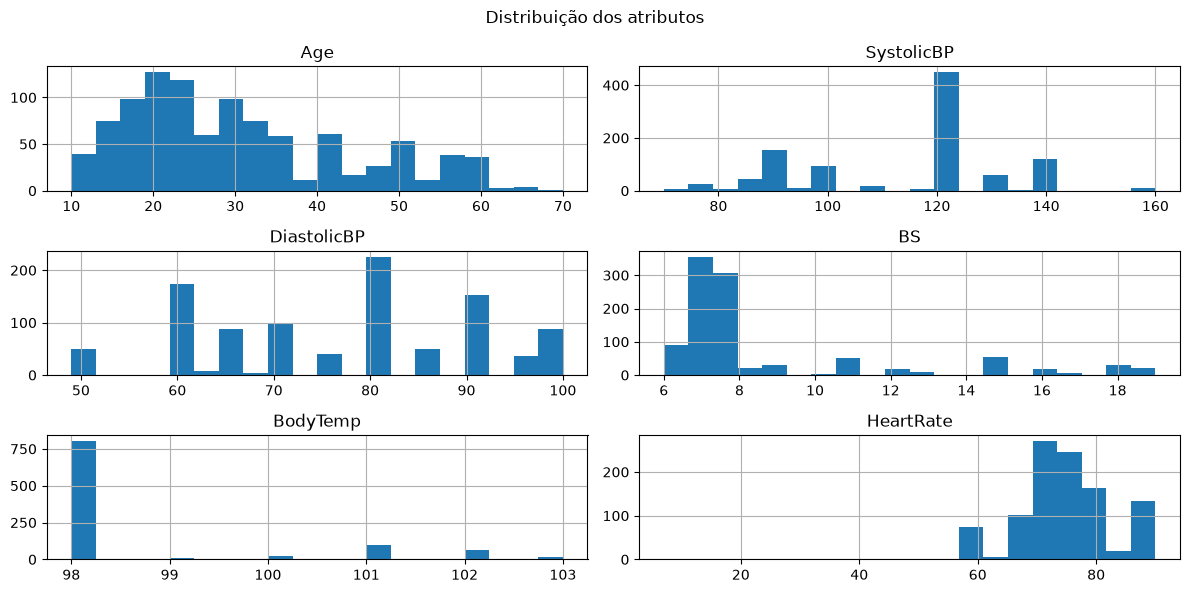

In [5]:
dataset[COLUNAS_ATRIBUTOS].hist(figsize=(12, 6), bins=20)
plt.suptitle("Distribuição dos atributos")
plt.tight_layout()
plt.show()

In [6]:
dataset[COLUNA_CLASSE_ORIGINAL].value_counts()

RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64

### 4.3 Registros duplicados

Antes de modelar, verificamos se existem linhas repetidas. Duplicatas são perigosas: se a mesma linha cair no
treino e no teste, o modelo é avaliado em um exemplo que já "decorou", e a métrica de teste fica inflada
(*data leakage*).

In [7]:
quantidade_duplicatas = dataset.duplicated().sum()
print(f"Linhas duplicadas: {quantidade_duplicatas} de {len(dataset)} "
      f"({quantidade_duplicatas / len(dataset):.0%})")

Linhas duplicadas: 562 de 1014 (55%)


**Mais da metade do dataset é composta de duplicatas exatas.** A documentação não indica que sejam medições
distintas de pacientes diferentes; com seis atributos inteiros, coincidências exatas em tamanha quantidade são
improváveis. Tratá-las como cópias do mesmo registro é a decisão mais conservadora: preferimos uma estimativa de
desempenho honesta a uma estimativa otimista.

## 5. Limpeza dos dados

Aplicamos duas regras, encapsuladas em uma função para deixar a decisão explícita e reutilizável:

1. remover duplicatas exatas;
2. remover registros com `HeartRate` abaixo de 40 bpm (erro de digitação identificado na análise exploratória).

In [8]:
FREQUENCIA_CARDIACA_MINIMA = 40


def limpar_dados(dados: pd.DataFrame) -> pd.DataFrame:
    """Remove duplicatas exatas e medições com frequência cardíaca fisiologicamente impossível."""
    sem_duplicatas = dados.drop_duplicates()
    valores_validos = sem_duplicatas["HeartRate"] >= FREQUENCIA_CARDIACA_MINIMA
    return sem_duplicatas[valores_validos].reset_index(drop=True)


dataset_limpo = limpar_dados(dataset)
print(f"Linhas após a limpeza: {len(dataset_limpo)}")
dataset_limpo[COLUNA_CLASSE_ORIGINAL].value_counts()

Linhas após a limpeza: 451


RiskLevel
low risk     233
high risk    112
mid risk     106
Name: count, dtype: int64

## 6. Formulação do problema: três classes ou triagem binária?

Antes de seguir com o problema de três classes, fazemos um diagnóstico rápido: avaliamos um SVM com padronização
por validação cruzada e olhamos o desempenho **por classe**.

In [9]:
X_tres_classes = dataset_limpo[COLUNAS_ATRIBUTOS]
y_tres_classes = dataset_limpo[COLUNA_CLASSE_ORIGINAL]
diagnostico = Pipeline([("transformacao", StandardScaler()), ("classificador", SVC(random_state=SEED))])
predicoes_diagnostico = cross_val_predict(diagnostico, X_tres_classes, y_tres_classes, cv=VALIDACAO_CRUZADA)
print(classification_report(y_tres_classes, predicoes_diagnostico))

              precision    recall  f1-score   support

   high risk       0.72      0.77      0.74       112
    low risk       0.73      0.91      0.81       233
    mid risk       0.47      0.19      0.27       106

    accuracy                           0.70       451
   macro avg       0.64      0.62      0.61       451
weighted avg       0.67      0.70      0.67       451



A classe **`mid risk` quase não é reconhecida** (recall baixo): com apenas esses seis sinais vitais, ela se
sobrepõe muito às classes vizinhas. Já a separação entre **alto risco** e as demais é bem mais nítida.

Como o objetivo de negócio é **priorizar gestantes de alto risco**, reformulamos o problema como uma **triagem
binária**:

- `HighRisk = 1` → alto risco (prioridade de acompanhamento);
- `HighRisk = 0` → risco baixo ou médio (acompanhamento de rotina).

In [10]:
dataset_modelo = dataset_limpo.assign(
    **{COLUNA_ALVO: (dataset_limpo[COLUNA_CLASSE_ORIGINAL] == "high risk").astype(int)}
).drop(columns=COLUNA_CLASSE_ORIGINAL)

dataset_modelo[COLUNA_ALVO].value_counts(normalize=True).rename("proporção")

HighRisk
0    0.751663
1    0.248337
Name: proporção, dtype: float64

A classe positiva representa cerca de **25%** dos dados, ou seja, o problema é **desbalanceado**. Isso tem duas
consequências para as próximas etapas:

- a acurácia sozinha engana (um modelo que sempre responde "não é alto risco" acertaria ~75%). Usaremos o
  **F1-score da classe alto risco** como métrica de otimização, porque ele equilibra recall e precisão;
- nos algoritmos que oferecem a opção (Árvore e SVM), usaremos `class_weight="balanced"`, que dá mais peso aos
  erros na classe minoritária durante o treino.

## 7. Separação entre treino e teste (holdout)

Reservamos **20%** dos dados para teste, com estratificação para manter a proporção de alto risco nos dois
conjuntos. O conjunto de teste **só será usado no final**, para avaliar os modelos já otimizados; toda a
comparação e a escolha de hiperparâmetros acontecem no conjunto de treino, com validação cruzada.

In [11]:
X = dataset_modelo[COLUNAS_ATRIBUTOS]
y = dataset_modelo[COLUNA_ALVO]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=PROPORCAO_TESTE, stratify=y, random_state=SEED
)
print(f"Treino: {len(X_treino)} linhas | Teste: {len(X_teste)} linhas")
print(f"Proporção de alto risco — treino: {y_treino.mean():.2f} | teste: {y_teste.mean():.2f}")

Treino: 360 linhas | Teste: 91 linhas
Proporção de alto risco — treino: 0.25 | teste: 0.25


## 8. Modelagem: comparação inicial dos algoritmos

Comparamos os quatro algoritmos estudados — **KNN, Árvore de Classificação (CART), Naive Bayes e SVM** — com
hiperparâmetros padrão, combinados com três tratamentos dos dados:

- **original**: sem transformação;
- **normalizado**: `MinMaxScaler`, que leva cada atributo para o intervalo [0, 1];
- **padronizado**: `StandardScaler`, que deixa cada atributo com média 0 e desvio padrão 1.

Cada combinação é montada como um **`Pipeline`**. Assim, dentro da validação cruzada, o *scaler* aprende média,
desvio, mínimo e máximo **apenas com os folds de treino** e só depois é aplicado ao fold de validação — evitando
*data leakage*.

In [12]:
ALGORITMOS = {
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
    "NB": GaussianNB(),
    "SVM": SVC(class_weight="balanced", random_state=SEED),
}
TRANSFORMACOES = {
    "original": "passthrough",
    "normalizado": MinMaxScaler(),
    "padronizado": StandardScaler(),
}


def criar_pipeline(transformacao, classificador) -> Pipeline:
    """Encadeia a transformação dos dados com o classificador."""
    return Pipeline([("transformacao", transformacao), ("classificador", classificador)])


def avaliar_com_validacao_cruzada(pipeline: Pipeline, X_avaliacao, y_avaliacao) -> np.ndarray:
    """Retorna o F1-score da classe alto risco em cada fold da validação cruzada."""
    return cross_val_score(pipeline, X_avaliacao, y_avaliacao, cv=VALIDACAO_CRUZADA, scoring="f1")


resultados_iniciais = {}
for nome_transformacao, transformacao in TRANSFORMACOES.items():
    for nome_algoritmo, algoritmo in ALGORITMOS.items():
        pipeline = criar_pipeline(transformacao, algoritmo)
        rotulo = f"{nome_algoritmo}-{nome_transformacao}"
        resultados_iniciais[rotulo] = avaliar_com_validacao_cruzada(pipeline, X_treino, y_treino)

resumo_inicial = pd.DataFrame(
    {"F1 médio": [f.mean() for f in resultados_iniciais.values()],
     "desvio padrão": [f.std() for f in resultados_iniciais.values()]},
    index=resultados_iniciais.keys(),
).sort_values("F1 médio", ascending=False)
resumo_inicial.round(3)

,F1 médio,desvio padrão
SVM-padronizado,0.765,0.084
SVM-normalizado,0.755,0.080
CART-padronizado,0.721,0.123
CART-original,0.715,0.122
CART-normalizado,0.715,0.122
SVM-original,0.655,0.076
KNN-padronizado,0.652,0.161
KNN-normalizado,0.630,0.145
NB-original,0.620,0.158
NB-normalizado,0.620,0.158


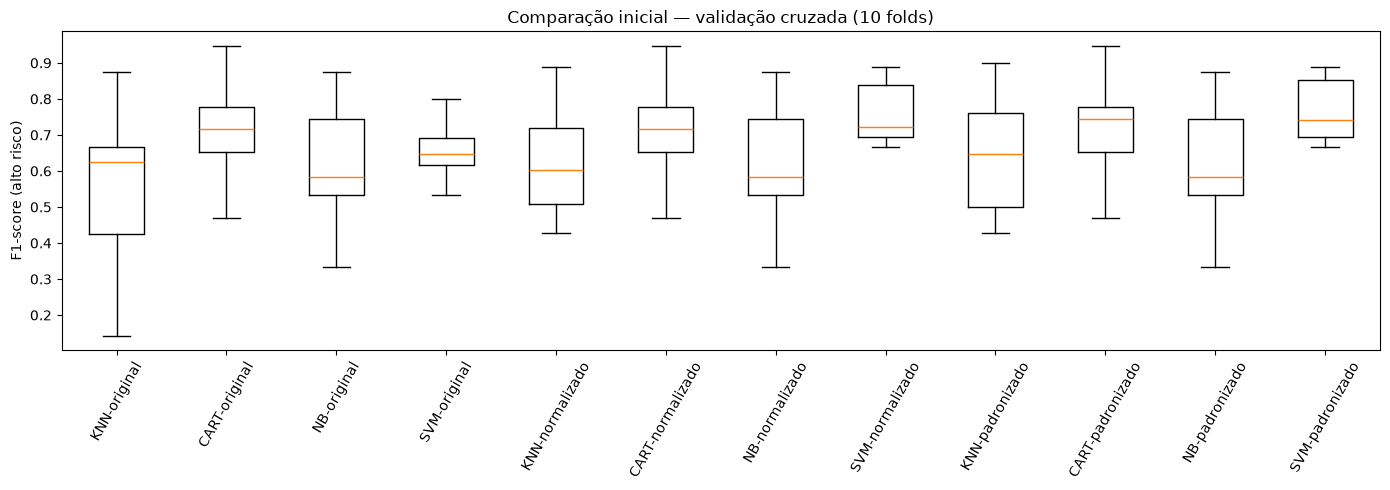

In [13]:
plt.figure(figsize=(14, 5))
plt.boxplot(list(resultados_iniciais.values()), tick_labels=list(resultados_iniciais.keys()))
plt.xticks(rotation=60)
plt.ylabel("F1-score (alto risco)")
plt.title("Comparação inicial — validação cruzada (10 folds)")
plt.tight_layout()
plt.show()

Observações da comparação inicial:

- **KNN e SVM** são os que mais variam com a escala dos dados, como esperado para algoritmos baseados em
  distância e em produto interno;
- a **Árvore** é praticamente indiferente à transformação, porque divide cada atributo por limiares e não compara
  atributos entre si;
- o **Naive Bayes Gaussiano** também é pouco afetado, pois modela cada atributo de forma independente.

A seguir otimizamos os hiperparâmetros de cada algoritmo, tratando a própria transformação como mais um
hiperparâmetro a ser escolhido.

## 9. Otimização de hiperparâmetros

Usamos `GridSearchCV`, que treina e avalia por validação cruzada (os mesmos 10 folds estratificados) todas as
combinações informadas, sempre sobre o conjunto de **treino**. Os hiperparâmetros variados seguem os vistos na
disciplina:

| Algoritmo | Hiperparâmetros |
|---|---|
| KNN | número de vizinhos (`n_neighbors`), métrica de distância (`metric`) e peso dos vizinhos (`weights`) |
| Árvore | profundidade máxima (`max_depth`), critério de divisão (`criterion`) e mínimo de amostras por folha (`min_samples_leaf`) |
| Naive Bayes | suavização da variância (`var_smoothing`) |
| SVM | rigidez da margem (`C`), tipo de kernel (`kernel`) e alcance do kernel RBF (`gamma`) |

Em todos os casos, a etapa `transformacao` do pipeline também varia entre original, normalizado e padronizado.

In [14]:
GRADES_HIPERPARAMETROS = {
    "KNN": {
        "classificador__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
        "classificador__metric": ["euclidean", "manhattan"],
        "classificador__weights": ["uniform", "distance"],
    },
    "CART": {
        "classificador__max_depth": [3, 4, 5, 7, 10, None],
        "classificador__criterion": ["gini", "entropy"],
        "classificador__min_samples_leaf": [1, 2, 5, 10],
    },
    "NB": {
        "classificador__var_smoothing": np.logspace(-9, -2, 8),
    },
    "SVM": {
        "classificador__C": [0.1, 1, 10, 100],
        "classificador__kernel": ["linear", "rbf"],
        "classificador__gamma": ["scale", 0.01, 0.1, 1],
    },
}


def otimizar_hiperparametros(nome_algoritmo: str) -> GridSearchCV:
    """Executa o grid search do algoritmo, incluindo a escolha da transformação dos dados."""
    grade = {"transformacao": list(TRANSFORMACOES.values()), **GRADES_HIPERPARAMETROS[nome_algoritmo]}
    busca = GridSearchCV(
        criar_pipeline("passthrough", ALGORITMOS[nome_algoritmo]),
        grade,
        cv=VALIDACAO_CRUZADA,
        scoring="f1",
        n_jobs=-1,
    )
    return busca.fit(X_treino, y_treino)


def descrever_transformacao(transformacao) -> str:
    """Traduz o objeto de transformação para o nome usado no relatório."""
    nomes = {"passthrough": "original", "MinMaxScaler": "normalizado", "StandardScaler": "padronizado"}
    chave = transformacao if isinstance(transformacao, str) else type(transformacao).__name__
    return nomes[chave]


buscas = {nome: otimizar_hiperparametros(nome) for nome in ALGORITMOS}

for nome, busca in buscas.items():
    parametros = {chave.replace("classificador__", ""): valor
                  for chave, valor in busca.best_params_.items() if chave != "transformacao"}
    print(f"{nome}: F1 (CV) = {busca.best_score_:.3f} | "
          f"transformação = {descrever_transformacao(busca.best_params_['transformacao'])} | {parametros}")

KNN: F1 (CV) = 0.675 | transformação = padronizado | {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}
CART: F1 (CV) = 0.763 | transformação = original | {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 10}
NB: F1 (CV) = 0.658 | transformação = original | {'var_smoothing': np.float64(0.01)}
SVM: F1 (CV) = 0.790 | transformação = original | {'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}


## 10. Avaliação dos modelos otimizados no conjunto de teste

Agora, pela primeira vez, usamos o conjunto de teste. Cada pipeline otimizado (já retreinado pelo `GridSearchCV`
com todo o conjunto de treino) prevê as gestantes que nunca viu.

In [15]:
def calcular_metricas(modelo, X_avaliacao, y_avaliacao) -> dict:
    """Calcula as métricas de classificação usadas no relatório e no teste automatizado."""
    predicoes = modelo.predict(X_avaliacao)
    return {
        "acurácia": accuracy_score(y_avaliacao, predicoes),
        "precisão (alto risco)": precision_score(y_avaliacao, predicoes),
        "recall (alto risco)": recall_score(y_avaliacao, predicoes),
        "F1 (alto risco)": f1_score(y_avaliacao, predicoes),
    }


comparacao_teste = pd.DataFrame(
    {nome: {"F1 (validação cruzada)": busca.best_score_,
            **calcular_metricas(busca.best_estimator_, X_teste, y_teste)}
     for nome, busca in buscas.items()}
).T.sort_values("F1 (validação cruzada)", ascending=False)
comparacao_teste.round(3)

,F1 (validação cruzada),acurácia,precisão (alto risco),recall (alto risco),F1 (alto risco)
SVM,0.790,0.879,0.773,0.739,0.756
CART,0.763,0.901,0.792,0.826,0.809
KNN,0.675,0.824,0.769,0.435,0.556
NB,0.658,0.835,0.833,0.435,0.571


### Escolha do modelo final

O modelo final é escolhido pelo **F1 da validação cruzada**, e não pelo resultado no teste. Escolher olhando o
teste transformaria o conjunto de teste em mais uma etapa de ajuste, e a estimativa de desempenho deixaria de
ser imparcial.

In [16]:
nome_modelo_final = max(buscas, key=lambda nome: buscas[nome].best_score_)
modelo_final = buscas[nome_modelo_final].best_estimator_
print(f"Modelo escolhido: {nome_modelo_final}")
modelo_final

Modelo escolhido: SVM


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformacao', ...), ('classificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",100
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",7
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3


                    precision    recall  f1-score   support

não alto risco (0)       0.91      0.93      0.92        68
    alto risco (1)       0.77      0.74      0.76        23

          accuracy                           0.88        91
         macro avg       0.84      0.83      0.84        91
      weighted avg       0.88      0.88      0.88        91



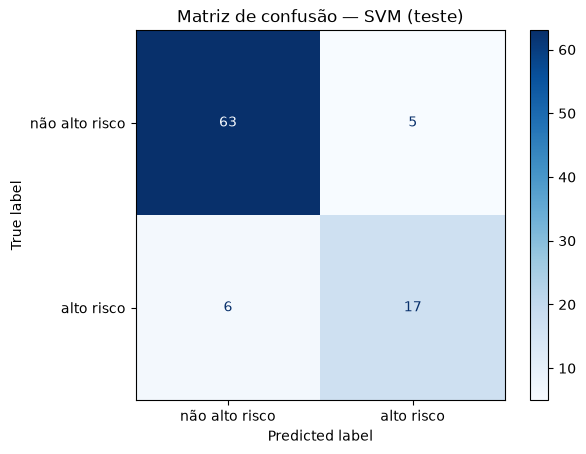

In [17]:
predicoes_teste = modelo_final.predict(X_teste)
print(classification_report(y_teste, predicoes_teste,
                            target_names=["não alto risco (0)", "alto risco (1)"]))

ConfusionMatrixDisplay.from_predictions(
    y_teste, predicoes_teste, display_labels=["não alto risco", "alto risco"], cmap="Blues"
)
plt.title(f"Matriz de confusão — {nome_modelo_final} (teste)")
plt.show()

## 11. Exportação do modelo

Exportamos o **pipeline completo** (transformação + classificador) com a biblioteca `pickle`. Assim, a aplicação
recebe os valores "crus" digitados no formulário e o próprio pipeline aplica a mesma transformação usada no treino.

**Decisão:** exportamos o modelo treinado **apenas com o conjunto de treino**, em vez de retreiná-lo com todos os
dados. Isso permite que o conjunto de teste continue inédito para o modelo e seja salvo como **golden dataset**,
usado pelo teste automatizado (PyTest) da aplicação para barrar a implantação de modelos que não atendam aos
requisitos de desempenho.

Após a execução, os dois arquivos aparecem no painel de arquivos do Colab e devem ser copiados para a pasta
`api/` do repositório.

In [18]:
with open(ARQUIVO_MODELO, "wb") as arquivo:
    pickle.dump(modelo_final, arquivo)

golden_dataset = X_teste.assign(**{COLUNA_ALVO: y_teste})
golden_dataset.to_csv(ARQUIVO_GOLDEN_DATASET, index=False)
print(f"Arquivos gerados: {ARQUIVO_MODELO} e {ARQUIVO_GOLDEN_DATASET} ({len(golden_dataset)} linhas)")

Arquivos gerados: modelo_risco_materno.pkl e golden_dataset_teste.csv (91 linhas)


Para garantir que a exportação funcionou, recarregamos o arquivo e verificamos que o modelo recarregado faz
exatamente as mesmas predições.

In [19]:
with open(ARQUIVO_MODELO, "rb") as arquivo:
    modelo_recarregado = pickle.load(arquivo)

assert (modelo_recarregado.predict(X_teste) == predicoes_teste).all()
print("Modelo recarregado produz as mesmas predições.")

Modelo recarregado produz as mesmas predições.


## 12. Simulação com dados novos

Simulamos o uso do modelo como faria a aplicação: três gestantes fictícias, com valores digitados como no
formulário.

In [20]:
novas_gestantes = pd.DataFrame(
    [
        {"Age": 23, "SystolicBP": 110, "DiastolicBP": 70, "BS": 7.0, "BodyTemp": 98.0, "HeartRate": 72},
        {"Age": 35, "SystolicBP": 140, "DiastolicBP": 95, "BS": 15.0, "BodyTemp": 98.0, "HeartRate": 88},
        {"Age": 30, "SystolicBP": 120, "DiastolicBP": 80, "BS": 7.5, "BodyTemp": 101.0, "HeartRate": 80},
    ],
    columns=COLUNAS_ATRIBUTOS,
)
novas_gestantes.assign(
    predicao=["alto risco" if p == 1 else "não alto risco" for p in modelo_recarregado.predict(novas_gestantes)]
)

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,predicao
0,23,110,70,7.0,98.0,72,não alto risco
1,35,140,95,15.0,98.0,88,alto risco
2,30,120,80,7.5,101.0,80,não alto risco


## 13. Boas práticas de desenvolvimento de software seguro aplicadas ao problema

Dados de saúde são **dados pessoais sensíveis** pela LGPD (art. 5º, II), o que exige cuidados em todo o ciclo do
sistema:

- **Minimização de dados:** o modelo usa apenas seis sinais vitais e a idade. Nome, CPF, número do prontuário ou
  endereço não são necessários para a predição e não devem ser coletados nem trafegados pela aplicação.
- **Anonimização e pseudonimização:** em um cenário real, o dataset de treino viria de prontuários. Antes de chegar
  à equipe de dados, os identificadores diretos devem ser removidos ou trocados por um pseudônimo (um *hash* com
  segredo guardado fora do dataset, para que o vínculo possa ser desfeito só por quem tem autorização).
- **Generalização contra reidentificação:** mesmo sem nome, a combinação idade + local + data pode identificar uma
  pessoa. Técnicas como faixas de idade (*k*-anonimato) ou supressão de valores raros reduzem esse risco. Aqui a
  idade em anos é mantida porque o dataset é público e já não tem outros quase-identificadores.
- **Privacidade na aplicação:** a API não armazena os dados enviados, valida cada campo na entrada (faixas
  fisiológicas plausíveis) e, em produção, deveria rodar só com HTTPS, autenticação dos profissionais de saúde e
  CORS restrito ao domínio do front-end.
- **Logs sem dados sensíveis:** registrar apenas metadados (horário, versão do modelo, latência), nunca os sinais
  vitais associados a uma pessoa.
- **Integridade do modelo:** arquivos `pickle` executam código ao serem carregados; o back-end só deve carregar
  modelos de origem confiável e versionada (por exemplo, publicados pelo pipeline de CI após passar no teste de
  desempenho), nunca arquivos enviados por usuários.

## 14. Análise dos resultados

**Principais achados**

1. **Qualidade dos dados importa mais que o algoritmo.** 55% do dataset original eram duplicatas exatas. Mantê-las
   faria a mesma gestante aparecer no treino e no teste e inflaria as métricas. Os valores de 85–90% de acurácia
   em três classes, comuns em análises públicas desse dataset, são em boa parte efeito desse vazamento.
2. **A formulação do problema foi decisiva.** Com três classes, a classe `mid risk` teve recall de apenas ~0,19 na
   validação cruzada. Como triagem binária (alto risco × demais), o problema ficou bem definido e alinhado ao
   objetivo de negócio.
3. **Escala dos dados.** Na comparação inicial, a padronização elevou o F1 do KNN de 0,55 para 0,65 e o do SVM de
   0,66 para 0,77, confirmando a sensibilidade desses algoritmos à escala. Árvore e Naive Bayes praticamente não
   mudaram.
4. **Modelo escolhido: SVM com kernel RBF** (`C = 100`, `class_weight = "balanced"`), com o melhor F1 na validação
   cruzada (0,79). Após a otimização, a versão sem transformação superou as versões normalizada e padronizada: um
   `C` alto compensa a diferença de escala neste conjunto pequeno. Como o `GridSearchCV` testou as três opções nos
   mesmos folds, a escolha é baseada em evidência, e não em suposição.
5. **Desempenho no teste (91 gestantes, 23 de alto risco):** acurácia de **0,88**, precisão de **0,77**, recall de
   **0,74** e F1 de **0,76** para a classe alto risco. Os valores são coerentes com a validação cruzada, sem sinal
   de *overfitting*.

**Pontos de atenção**

- **Conjunto de teste pequeno:** com 23 casos positivos, cada gestante classificada errada move o recall em cerca
  de 4 pontos percentuais. O desvio padrão entre os folds (~0,08 de F1) mostra que as métricas devem ser lidas como
  faixas, e não como valores exatos.
- **A Árvore teve recall maior no teste (0,83 contra 0,74 do SVM).** Não a escolhemos porque a decisão foi tomada
  na validação cruzada, onde o SVM foi superior; trocar de modelo por causa do teste seria ajustar ao teste. Ainda
  assim, a Árvore é uma alternativa forte e tem a vantagem da **explicabilidade**, que pode pesar em um contexto
  clínico.
- **Falsos negativos:** cerca de 1 em cada 4 gestantes de alto risco não foi sinalizada. Em produção, o modelo
  deve ser apenas um alerta adicional, nunca o único critério de triagem. Um próximo passo seria ajustar o limiar
  de decisão para priorizar o recall, aceitando mais falsos positivos.
- **Generalização:** os dados vêm de uma única região (Bangladesh), com temperatura em °F e poucos atributos. O
  modelo precisaria ser revalidado com dados da população em que seria usado.
- **Versão do scikit-learn:** o arquivo `pickle` deve ser carregado com a mesma versão usada no treino; a versão é
  impressa no início do notebook e fixada no `requirements.txt` da aplicação.

## 15. Conclusão

Partimos de um dataset público de saúde materna e seguimos o processo estudado na disciplina: carga por URL,
análise exploratória, limpeza, holdout estratificado, comparação de KNN, Árvore, Naive Bayes e SVM com dados
originais, normalizados e padronizados (sempre dentro de `Pipeline`, para evitar *data leakage*), otimização de
hiperparâmetros com `GridSearchCV` e validação cruzada estratificada, avaliação no conjunto de teste e exportação
do pipeline com `pickle`.

As decisões mais importantes não foram de algoritmo, mas de **engenharia dos dados e do problema**: remover
duplicatas, corrigir a formulação para uma triagem binária e escolher métricas que refletem o custo real dos erros
(recall e F1 da classe alto risco). O resultado é um SVM com 88% de acurácia e 74% de recall de alto risco em
dados inéditos.

O modelo exportado é carregado de forma embarcada pela aplicação full stack (back-end em FastAPI e front-end em
HTML/CSS/JS). O golden dataset gerado aqui alimenta o teste automatizado com PyTest, que impede a implantação de
um modelo substituto que não atinja os requisitos mínimos de desempenho.